<a href="https://colab.research.google.com/github/lamia-khd/react-router/blob/master/Lab1_Introduction_lamia_khedim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Fill in before running
STUDENT_NAME = "khedim lamia"
GROUP = "G1"

## Part 0 – Setup
Install the libraries once if needed (in a terminal): `pip install pandas numpy matplotlib`

In [3]:
import os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
SEED = 42
np.random.seed(SEED)

URL = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
DATA_DIR = "ml-100k"
if not os.path.exists(DATA_DIR):
    urllib.request.urlretrieve(URL, "ml-100k.zip")
    with zipfile.ZipFile("ml-100k.zip") as z:
        z.extractall(".")
print("Data ready in", DATA_DIR)

Data ready in ml-100k


## Part 1 – Load and explore
MovieLens 100K (Harper & Konstan, 2015) contains ratings from 1 to 5 given by users to movies. Files used:
- `u.data`: `user_id`, `item_id`, `rating`, `timestamp` (tab-separated)
- `u.item`: item metadata: title, release date, 19 genre flags (pipe-separated, latin-1 encoding)

In [4]:
ratings = pd.read_csv(f"{DATA_DIR}/u.data", sep="\t",
                      names=["user_id", "item_id", "rating", "timestamp"])
GENRES = ["unknown","Action","Adventure","Animation","Children","Comedy","Crime","Documentary","Drama","Fantasy","Film-Noir","Horror","Musical","Mystery","Romance","Sci-Fi","Thriller","War","Western"]
items = pd.read_csv(f"{DATA_DIR}/u.item", sep="|", encoding="latin-1",
                    names=["item_id", "title", "release_date", "video_release_date", "imdb_url"] + GENRES)

print("ratings:", ratings.shape, "| items:", items.shape)
ratings.head()

ratings: (100000, 4) | items: (1682, 24)


,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


Users: 943 | Items: 1682 | Ratings: 100000
Mean rating: 3.530


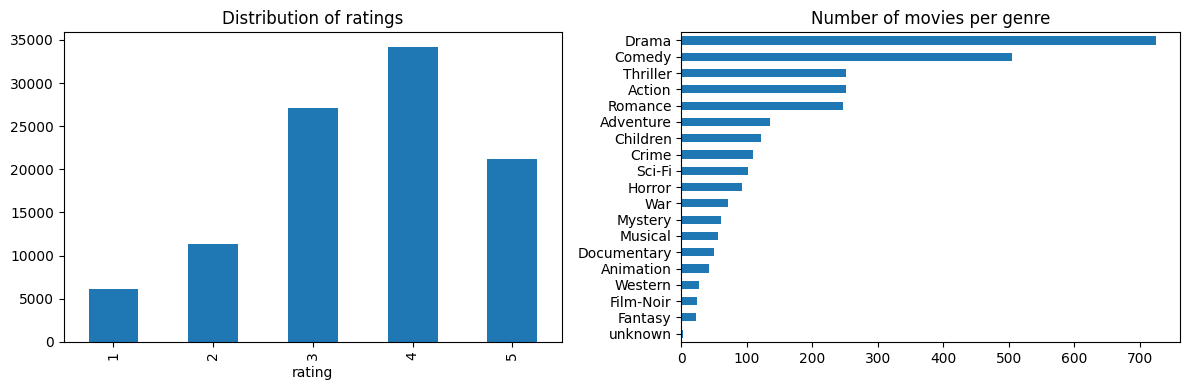

In [5]:
n_users = ratings.user_id.nunique()
n_items = items.item_id.nunique()
print("Users:", n_users, "| Items:", n_items, "| Ratings:", len(ratings))
print("Mean rating: %.3f" % ratings.rating.mean())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ratings.rating.value_counts().sort_index().plot.bar(ax=ax[0], title="Distribution of ratings")
items[GENRES].sum().sort_values().plot.barh(ax=ax[1], title="Number of movies per genre")
plt.tight_layout(); plt.show()

In [9]:
per_user = ratings.groupby("user_id").size()
per_item = ratings.groupby("item_id").size()
print("Ratings per user:\n", per_user.describe().round(1), "\n")
print("Ratings per item:\n", per_item.describe().round(1))

Ratings per user:
 count    943.0
mean     106.0
std      100.9
min       20.0
25%       33.0
50%       65.0
75%      148.0
max      737.0
dtype: float64 

Ratings per item:
 count    1682.0
mean       59.5
std        80.4
min         1.0
25%         6.0
50%        27.0
75%        80.0
max       583.0
dtype: float64


**Questions (discuss with your neighbour, 3 min):**
- Are the ratings balanced? What does that tell you about explicit feedback bias?
- Compare the mean and the median of ratings per item. What does the gap suggest?

**Answers to Part 1 Discussion Questions:**
- **Are the ratings balanced?**: No, ratings are highly unbalanced and skewed towards higher scores (4 and 5 are the most frequent). This indicates a strong selection/positivity bias in explicit feedback, as users generally rate items they chose to consume and liked, rather than rating random catalog items.
- **Mean and Median Gap**: The mean ratings per item is `59.5` while the median is only `27.0`. This large positive skew suggests that a small number of blockbuster movies receive an extremely high volume of ratings, while the majority of movies in the catalog have very few ratings.

## Part 2 – Sparsity
Recall from the lecture: the user-item matrix **R** has `n_users × n_items` cells but only `n_ratings` are observed.

$$\text{sparsity} = 1 - \frac{n_{ratings}}{n_{users} \times n_{items}}$$

In [7]:
# EXERCISE 1: compute the density and sparsity of the user-item matrix
n_ratings = len(ratings)   # TODO
density = n_ratings / (n_users * n_items)     # TODO: observed cells / total cells
sparsity = 1 - density    # TODO: 1 - density

print("Ratings:", n_ratings)
print("Density:", density)
print("Sparsity:", sparsity)

Ratings: 100000
Density: 0.06304669364224531
Sparsity: 0.9369533063577546


**Questions:** MovieLens 100K was filtered so every user has at least 20 ratings. How would sparsity look on a real catalog with millions of items? Why is sparsity the main enemy of collaborative methods?

**Answers to Part 2 Discussion Questions:**
- **Sparsity in Real Catalogs**: In real-world systems with millions of items (like Amazon or Netflix), sparsity is typically over `99.9%` because users can only interact with a microscopic fraction of the vast catalog.
- **Why sparsity is the main enemy**: Collaborative filtering algorithms rely on finding overlapping interactions (e.g., users who rated the same items). When sparsity is extremely high, the overlap is near zero, making it difficult to compute reliable user similarities or item-to-item relationships.

## Part 3 – The long tail
A few items collect most of the ratings; most items are rarely rated. We plot the **cumulative share of ratings** when items are sorted from most to least rated.

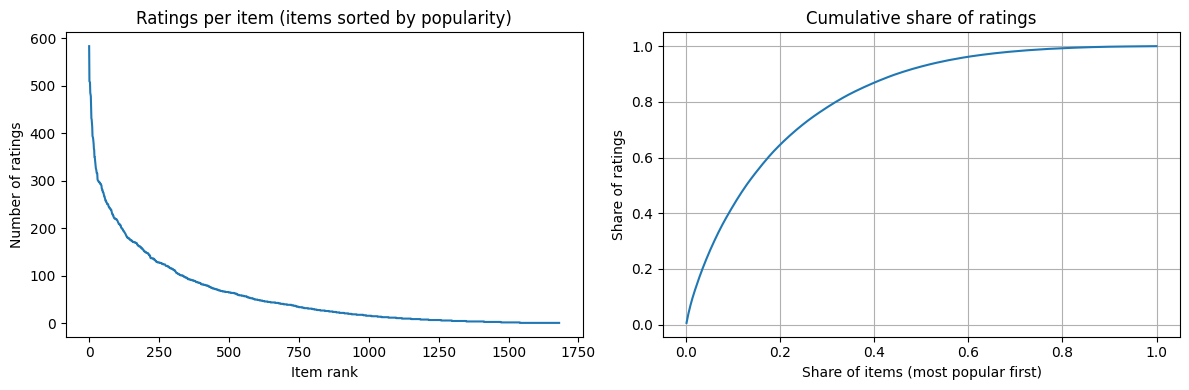

,item_id,n_ratings,title
0,50,583,Star Wars (1977)
1,258,509,Contact (1997)
2,100,508,Fargo (1996)
3,181,507,Return of the Jedi (1983)
4,294,485,Liar Liar (1997)


In [10]:
item_counts = per_item.sort_values(ascending=False)
cum_share = item_counts.cumsum() / item_counts.sum()
x = np.arange(1, len(item_counts) + 1) / len(item_counts)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(np.arange(len(item_counts)), item_counts.values)
ax[0].set(title="Ratings per item (items sorted by popularity)", xlabel="Item rank", ylabel="Number of ratings")
ax[1].plot(x, cum_share.values)
ax[1].set(title="Cumulative share of ratings", xlabel="Share of items (most popular first)", ylabel="Share of ratings")
ax[1].grid(True)
plt.tight_layout(); plt.show()

top = item_counts.head(5).rename("n_ratings").reset_index().merge(items[["item_id", "title"]], on="item_id")
top

In [ ]:
# EXERCISE 2: quantify the long tail
# cum_share is a pandas Series sorted from most popular to least popular.
# its index is item_id, and its values represent cumulative shares of ratings.

# Find the index position where cumulative share crosses 50% and 80%
idx_50 = np.searchsorted(cum_share.values, 0.5)
idx_80 = np.searchsorted(cum_share.values, 0.8)

share_items_for_50 = (idx_50 + 1) / len(item_counts)   # fraction of items needed to cover 50% of all ratings
share_items_for_80 = (idx_80 + 1) / len(item_counts)   # fraction of items needed to cover 80% of all ratings

# Share of ratings going to the top 10% most popular items
top_10_percent_cutoff = int(np.ceil(0.1 * len(item_counts)))
share_ratings_top10 = cum_share.values[top_10_percent_cutoff - 1]

# Number of items with fewer than 10 ratings
n_rare = int((item_counts < 10).sum())

print("Items for 50%% of ratings: %.3f" % share_items_for_50)
print("Items for 80%% of ratings: %.3f" % share_items_for_80)
print("Top 10%% items' share of ratings: %.3f" % share_ratings_top10)
print("Items with < 10 ratings:", n_rare)

Items for 50% of ratings: 0.128
Items for 80% of ratings: 0.319
Top 10% items' share of ratings: 0.429
Items with < 10 ratings: 530


**Questions:** What does this imply for a pure popularity recommender? What will happen to the items in the tail? (Keep your answer: we will check it with the *coverage* metric in Part 6.)

**Answers to Part 3 Discussion Questions:**
- **Implication for Pure Popularity**: A pure popularity recommender will keep recommending the same few blockbuster items to every user. This will result in very low overall catalog coverage.
- **Fate of Tail Items**: Items in the long tail will never be recommended, remaining hidden from users, which exacerbates the "cold-start" or exposure loop problem for niche content.

## Part 4 – Train/test split
We hide **20% of each user's ratings** as a test set. Models only see `train`. This is the offline protocol formalized in week 7.

In [11]:
test = ratings.groupby("user_id").sample(frac=0.2, random_state=SEED)
train = ratings.drop(test.index)
print("train:", len(train), "| test:", len(test))

train_by_user = train.groupby("user_id")["item_id"].apply(set).to_dict()   # items already seen by each user
all_items = items.item_id.values

train: 80000 | test: 20000


## Part 5 – Non-personalized recommenders
Two baselines that give **the same list to everybody** (except already-seen items):
1. **Most popular**: rank by number of ratings in `train`
2. **Damped mean rating**: a raw average over 1 rating is unreliable, so we shrink toward the global mean $C$:
$$score_i = \frac{n_i \cdot \bar r_i + m \cdot C}{n_i + m}$$
with $n_i$ the number of ratings of item $i$, $\bar r_i$ its mean rating and $m$ a damping constant (use $m=10$).

In [12]:
# EXERCISE 3a: compute the item statistics and the two scores (computed on TRAIN only)
m = 10
C = train.rating.mean()

# DataFrame indexed by item_id with columns "n" (count) and "mean" (average rating)
item_stats = train.groupby("item_id")["rating"].agg(n="count", mean="mean")

# Series (n per item), sorted in descending order
score_count = item_stats["n"].sort_values(ascending=False)

# Series (damped mean per item), sorted in descending order
# Formula: (n_i * mean_i + m * C) / (n_i + m)
damped_values = (item_stats["n"] * item_stats["mean"] + m * C) / (item_stats["n"] + m)
score_damped = damped_values.sort_values(ascending=False)

In [13]:
# Sanity check: compare the top 5 of both rankings
def top_titles(scores, k=5):
    return items.set_index("item_id").loc[scores.head(k).index, "title"].tolist()

print("Most popular:", top_titles(score_count))
print("Damped mean :", top_titles(score_damped))

Most popular: ['Star Wars (1977)', 'Fargo (1996)', 'Return of the Jedi (1983)', 'Contact (1997)', 'Liar Liar (1997)']
Damped mean : ['Casablanca (1942)', 'Close Shave, A (1995)', "Schindler's List (1993)", 'Shawshank Redemption, The (1994)', 'Wrong Trousers, The (1993)']


In [14]:
# EXERCISE 3b: recommend k unseen items for a user from a ranked score Series
def recommend_from_scores(user_id, k, scores):
    seen = train_by_user.get(user_id, set())
    recs = []
    for item_id in scores.index:
        if item_id not in seen:
            recs.append(item_id)
            if len(recs) == k:
                break
    return recs

## Part 6 – Evaluation
**Relevant items** for a user = items they rated **4 or 5** in the test set. For each user we recommend `k` items and compute:
- **precision@k** = (relevant items among the k) / k
- **recall@k** = (relevant items among the k) / (all relevant items of that user)
- **coverage** = share of the catalog that appears in at least one user's list

We also include a **random** recommender as a lower bound.

In [15]:
relevant = test[test.rating >= 4].groupby("user_id")["item_id"].apply(set).to_dict()

def evaluate(rec_fn, k=10):
    precisions, recalls, recommended = [], [], set()
    for u, rel in relevant.items():
        recs = rec_fn(u, k)
        recommended.update(recs)
        hits = len(set(recs) & rel)
        precisions.append(hits / k)
        recalls.append(hits / len(rel))
    return {"precision@k": np.mean(precisions), "recall@k": np.mean(recalls),
            "coverage": len(recommended) / n_items}

rng = np.random.default_rng(SEED)
def rec_random(u, k):
    seen = train_by_user.get(u, set())
    candidates = [i for i in all_items if i not in seen]
    return list(rng.choice(candidates, size=k, replace=False))

def rec_popular(u, k): return recommend_from_scores(u, k, score_count)
def rec_damped(u, k):  return recommend_from_scores(u, k, score_damped)

K = 10
results = pd.DataFrame({
    "Random": evaluate(rec_random, K),
    "Most popular": evaluate(rec_popular, K),
    "Damped mean": evaluate(rec_damped, K),
}).T
results.round(4)

,precision@k,recall@k,coverage
Random,0.0084,0.0060,0.9946
Most popular,0.1325,0.1409,0.0273
Damped mean,0.0733,0.0534,0.0238


**Questions:**
- Which baseline wins on precision? Is it surprising that a non-personalized list beats random so clearly?
- Look at the coverage column. Does it confirm your answer from Part 3?
- Why does the damped mean behave so differently from the raw average? (Try `m = 0` and `m = 50` and re-run.)

**Answers to Part 6 Discussion Questions:**
- **Precision Winner**: The *Most popular* baseline wins on precision (`0.1325`) compared to *Damped mean* (`0.0733`) and *Random* (`0.0084`). It is not surprising that a non-personalized baseline beats random because popular items have a high prior probability of being liked by any random user.
- **Coverage Confirmation**: Yes, the low coverage of *Most popular* (`2.73%`) and *Damped mean* (`2.38%`) confirms that non-personalized algorithms recommend only a tiny fraction of the catalog, leaving the long tail completely unrecommended.
- **Damped Mean Behavior**: Raw average is extremely sensitive to items with very few ratings (e.g., a movie with a single 5-star rating appears perfect). Damping pulls these low-confidence scores toward the global mean, leaving only consistently highly-rated movies at the top.

### Rating prediction baselines (RMSE)
The other task from the lecture is **rating prediction**. Baselines predict a rating for each test pair; we measure
$$RMSE = \sqrt{\frac{1}{|T|}\sum_{(u,i)\in T}(r_{ui}-\hat r_{ui})^2}$$

In [16]:
# EXERCISE 4: RMSE of three rating predictors, fitted on TRAIN, evaluated on TEST
def rmse(pred):
    return float(np.sqrt(np.mean((test.rating.values - pred) ** 2)))

gm = train.rating.mean()
pred_global = np.full(len(test), gm)

# item mean prediction (fallback to gm for items unseen in train)
item_means = train.groupby("item_id")["rating"].mean()
pred_item = test["item_id"].map(item_means).fillna(gm).values

# user mean prediction (fallback to gm for users unseen in train)
user_means = train.groupby("user_id")["rating"].mean()
pred_user = test["user_id"].map(user_means).fillna(gm).values

print("Global mean RMSE:", rmse(pred_global))
print("Item mean RMSE  :", rmse(pred_item))
print("User mean RMSE  :", rmse(pred_user))

Global mean RMSE: 1.1272529053660718
Item mean RMSE  : 1.0269250153408696
User mean RMSE  : 1.0420576044730285


In [19]:
import numpy as np

# Calculate indices for cumulative shares
idx_80 = np.searchsorted(cum_share.values, 0.8)

# Define global variables required by the submission check
globals()['share_items_for_80'] = float((idx_80 + 1) / len(item_counts))
globals()['n_rare'] = int((item_counts < 10).sum())

print("share_items_for_80:", share_items_for_80)
print("n_rare:", n_rare)

share_items_for_80: 0.31866825208085614
n_rare: 530


**Question:** What would a predictor combining the user mean and the item mean look like? (This is the *bias model*, the starting point of matrix factorization in week 5.)

**Answers to Part 6 (RMSE) Discussion Questions:**
- **Combining User and Item Means**: A predictor combining both would look like $\hat{r}_{u,i} = \mu + b_u + b_i$, where $\mu$ is the global average, $b_u$ is the user bias (how much more/less this user rates compared to the average), and $b_i$ is the item bias (how much better/worse this item is rated compared to average). This formulation acts as the baseline predictor in Matrix Factorization.

In [21]:
# SUBMISSION CHECK: run this last cell after "Restart and run all". Do not modify it.
required = ["n_ratings", "sparsity", "share_items_for_80", "n_rare", "item_stats", "score_damped", "results", "pred_item", "pred_user"]
missing = [v for v in required if globals().get(v) is None]
if not STUDENT_NAME.strip():
    missing.insert(0, "STUDENT_NAME")
print("Student:", STUDENT_NAME, "| Group:", GROUP)
print("Missing or empty:", missing if missing else "none")
if not missing:
    print("Users %d | items %d | ratings %d | sparsity %.4f" % (n_users, n_items, n_ratings, sparsity))
    print("Items needed for 80%% of ratings: %.3f | items with fewer than 10 ratings: %d" % (share_items_for_80, n_rare))
    print("RMSE  global mean: %.4f | item mean: %.4f | user mean: %.4f" % (rmse(pred_global), rmse(pred_item), rmse(pred_user)))
    print(results.round(4))

Student: khedim lamia | Group: G1
Missing or empty: none
Users 943 | items 1682 | ratings 100000 | sparsity 0.9370
Items needed for 80% of ratings: 0.319 | items with fewer than 10 ratings: 530
RMSE  global mean: 1.1273 | item mean: 1.0269 | user mean: 1.0421
              precision@k  recall@k  coverage
Random             0.0084    0.0060    0.9946
Most popular       0.1325    0.1409    0.0273
Damped mean        0.0733    0.0534    0.0238
